## Анализ и прогнозирование временных рядов методами искусственного интеллекта

### **Практическая работа 7. Востановление пропусков и прогноз значений временного ряда.**


#### **7.1 Аналитечкие методы востановления временного ряда**

##### *Краткое описание*

В данном пункте практической работы вам предстоит познакомиться с базовыми, аналитическими методами восстановления временных рядов.
Для выполнения данного пункта из каждой группы методов, представленных в ***табл. 7.1*** вам необходимо выбрать по одному методу восстановления ряда. При работе с первой группой, вам необходимо самостоятельно реализовать выбранный метод.  

**Табл. 7.1** - Группы аналитических методов восстановления.
№|Название группы|Модели и методы|
--|----|----|
1|Заполнение существующими значениями ряда|Средним, медианной, Hot-Deck|
2|Заполнение на основе близки значений|[Интерполяция](https://scikit-learn.org/stable/auto_examples/linear_model/plot_polynomial_interpolation.html),  [KNNi](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html)|
3|На основе матричных разложений|[CD-Rec](#Fixme:Дат ссылку), [SVD](https://pypi.org/project/fancyimpute/)|

##### 7.1.1 Загрузка и подготовка данных

In [1]:
from pathlib import Path
from time import perf_counter
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from modules.imputation import add_nan, hot_deck, rolling_window, iterative_svd, masked_metrics
from modules.models import LinearModel, TimeAE, train_model, reconstruct

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
cache = Path('.cache')
cache.mkdir(exist_ok=True)
assert Path('datasets').is_dir(), 'Откройте ноутбук из каталога практики 7.'
print('Устройство: CPU; потоков:', torch.get_num_threads())

Устройство: CPU; потоков: 4


In [2]:
path_data = Path('datasets') / 'madrid.txt'
madrid_matrix = np.loadtxt(path_data)
assert madrid_matrix.shape == (25000, 10) and np.isfinite(madrid_matrix).all()
madrid = madrid_matrix[:, 0]
print('Madrid:', madrid_matrix.shape, '; аналитические методы: первый канал')

Madrid: (25000, 10) ; аналитические методы: первый канал


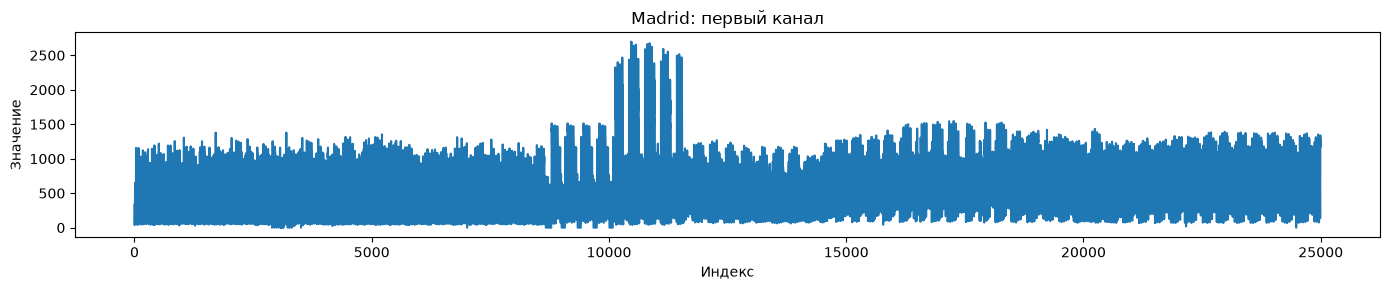

In [3]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(madrid)
ax.set(title='Madrid: первый канал', xlabel='Индекс', ylabel='Значение')
plt.tight_layout()
plt.show()

Самостоятельно реализуйте функцию, принимающую на вход многомерный временной ряд и возвращающий:
1. Все подпоследовательности временного ряда, в которых некоторые значения временного ряда были заменены nan значениями.
2. Индексы пропущенных значений
   
Процент пропущенных значений должен регулироваться отдельным параметром.


In [4]:
# add_nan самостоятельно реализована в modules/imputation.py.
madrid_with_nan, index = add_nan(madrid, percent=.25, seed=SEED)
print('Искусственно скрыто:', index.sum(), 'из', madrid.size)

Искусственно скрыто: 6250 из 25000


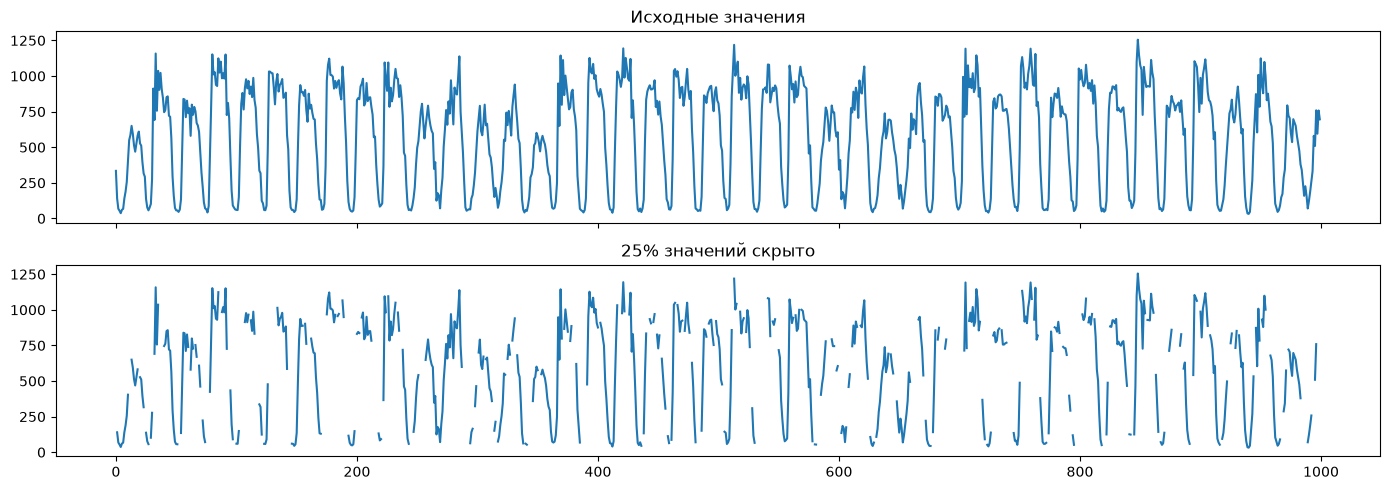

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axes[0].plot(madrid[:1000]); axes[0].set_title('Исходные значения')
axes[1].plot(madrid_with_nan[:1000]); axes[1].set_title('25% значений скрыто')
plt.tight_layout()
plt.show()

In [6]:
recovery = {}

##### 7.1.2 Заполнение существующими значениями ряда


In [7]:
madrid_mean = np.where(index, np.nanmean(madrid_with_nan), madrid_with_nan)
recovery['Mean'] = madrid_mean

In [8]:
print('Среднее наблюдаемых значений:', np.nanmean(madrid_with_nan))

Среднее наблюдаемых значений: 644.12576


In [9]:
madrid_median = np.where(index, np.nanmedian(madrid_with_nan), madrid_with_nan)

In [10]:
recovery['Median'] = madrid_median

In [11]:
print('Медиана наблюдаемых значений:', np.nanmedian(madrid_with_nan))

Медиана наблюдаемых значений: 627.5


Самостоятельно реализуйте один метод из первой группы ***табл. 7.1*** и проведите постановление данных, сохранив результаты восстановления.

In [12]:
# Самостоятельный Hot-Deck: наблюдение справа, затем слева.
madrid_hot_deck = hot_deck(madrid_with_nan)

In [13]:
recovery['Hot-Deck'] = madrid_hot_deck

In [14]:
assert np.array_equal(madrid_hot_deck[~index], madrid[~index])

##### 7.1.3 Заполнение на основе близких значений


Используя документацию одного из методов восстановления второй группы ***табл. 7.1*** и проведите восстановление данных, сохранив результаты восстановления.

In [15]:
imputer = KNNImputer(n_neighbors=18)

In [16]:
madrid_slice = rolling_window(madrid_with_nan, window=100, step=100)
assert madrid_slice.shape == (250, 100)

In [17]:
madrid_knn = imputer.fit_transform(madrid_slice).ravel()
recovery['KNN'] = np.where(index, madrid_knn, madrid)

In [18]:
assert np.isfinite(recovery['KNN']).all()

##### 7.1.4 Заполнение на матричных преобразований

Используя документацию одного из методов восстановления третей группы ***табл. 7.1*** и проведите восстановление данных, сохранив результаты восстановления.

In [19]:
# NumPy SVD не требует fancyimpute и дополнительных установок.

In [20]:
print('SVD: rank=2, max_iter=100, tolerance=1e-5')

SVD: rank=2, max_iter=100, tolerance=1e-5


In [21]:
svd_started = perf_counter()

In [22]:
madrid_svd = iterative_svd(madrid_slice, rank=2, max_iter=100, tolerance=1e-5).ravel()
recovery['SVD'] = madrid_svd
print(f'Время SVD: {perf_counter()-svd_started:.3f} с')

Время SVD: 0.094 с


In [23]:
assert np.array_equal(madrid_svd[~index], madrid[~index])

##### 7.1.5 Сравнение результатов восстановления.

Для каждой группы методов постройте методов основные метрики оценки качества постановления.
На основе метрик отберите лучшие методы постановления метрик и выберите лучшую группу методов.
Для лучших методов из каждой группы постройте графики сравнения реальных и восстановленных данных. Объясните результаты и сделайте вывод.



In [24]:
analytic_metrics = pd.DataFrame({name: masked_metrics(madrid, values, index)
                                 for name, values in recovery.items()}).T
for values in recovery.values():
    np.testing.assert_array_equal(values[~index], madrid[~index])
    assert np.isfinite(values).all()
display(analytic_metrics)
groups = {'Значения ряда': ['Mean', 'Median', 'Hot-Deck'],
          'Близкие значения': ['KNN'], 'Матричные разложения': ['SVD']}
best_methods = {group: analytic_metrics.loc[methods, 'RMSE'].idxmin()
                for group, methods in groups.items()}
best_analytic = analytic_metrics['RMSE'].idxmin()
print('Лучший метод по RMSE:', best_analytic)

,MSE,RMSE,MAE,R2
Mean,159462.488942,399.327546,339.282959,-0.000505
Median,160037.349200,400.046684,339.503200,-0.004112
Hot-Deck,42307.422720,205.687682,124.791680,0.734553
KNN,49725.811481,222.992851,163.553191,0.688008
SVD,109434.818261,330.809338,268.258414,0.313380


Лучший метод по RMSE: Hot-Deck


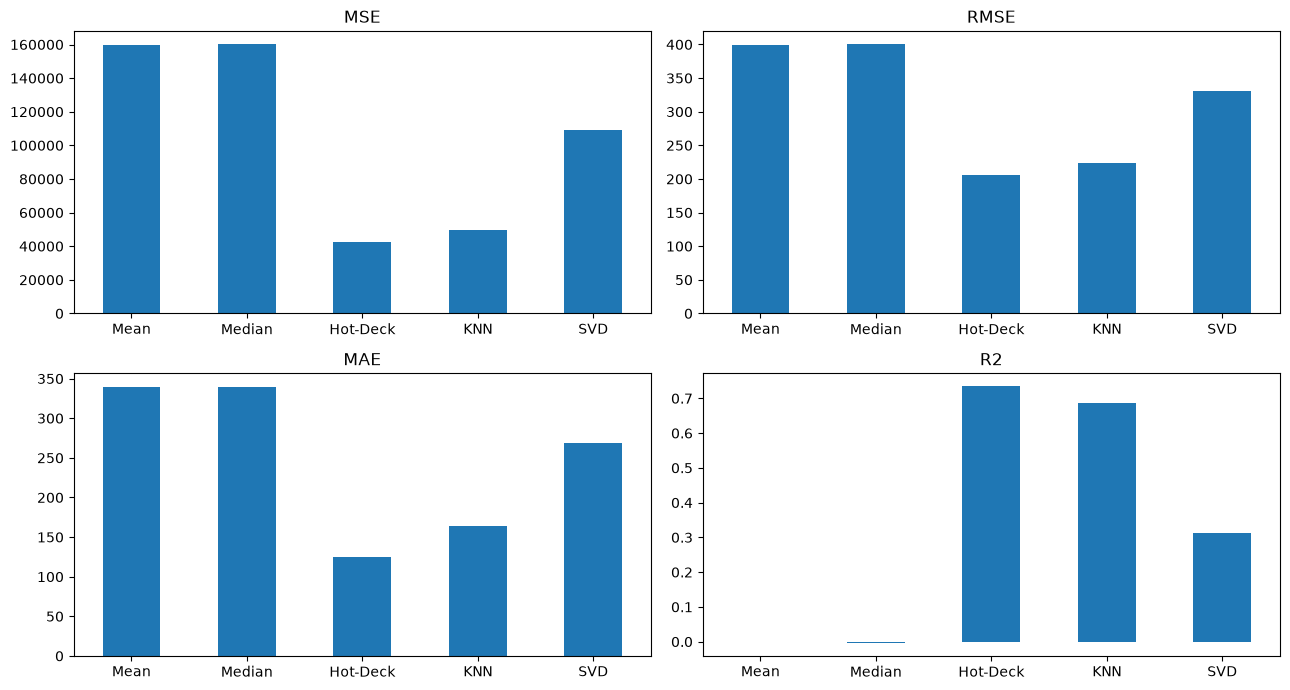

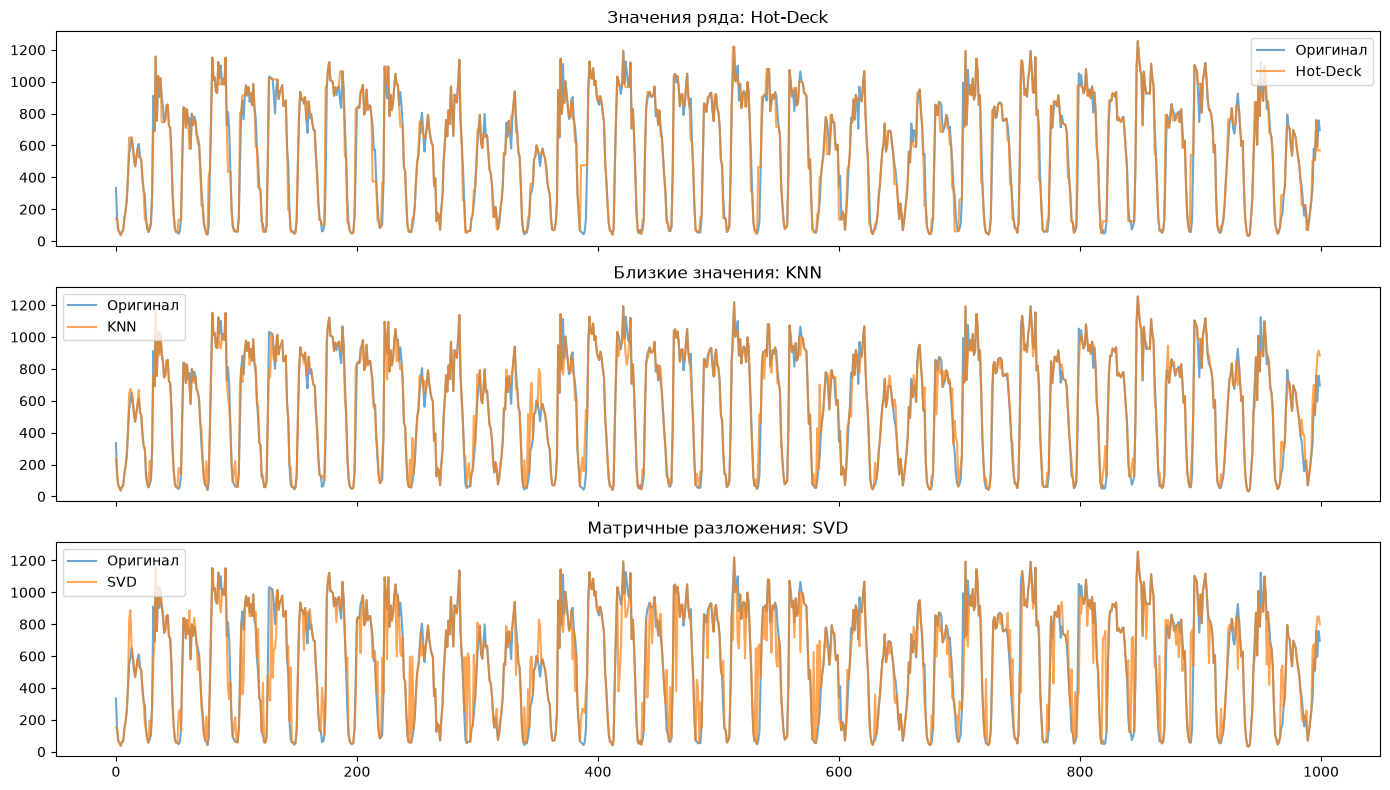

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, metric in zip(axes.flat, ['MSE', 'RMSE', 'MAE', 'R2']):
    analytic_metrics[metric].plot.bar(ax=ax, rot=0, title=metric)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (group, name) in zip(axes, best_methods.items()):
    ax.plot(madrid[:1000], label='Оригинал', alpha=.65)
    ax.plot(recovery[name][:1000], label=name, alpha=.7)
    ax.set_title(f'{group}: {name}')
    ax.legend()
plt.tight_layout()
plt.show()

*Вывод.* На общей маске 6250 скрытых значений первого канала лучшим оказался **Hot-Deck**, RMSE **205.6877**. Из трёх групп выбранные методы: Значения ряда — Hot-Deck, Близкие значения — KNN, Матричные разложения — SVD.

Среднее и медиана не используют локальное изменение ряда; KNN сравнивает окна длиной 100, а SVD использует приближение ранга 2. Метрики рассчитаны только на искусственно скрытых значениях, поэтому сохранение наблюдаемых точек не завышает оценку качества. Все наблюдаемые значения оставлены неизменными. Победа конкретного метода относится к этой маске случайных пропусков и не доказывает превосходства при длинных непрерывных разрывах.

#### **7.2 Нейросетевые методы востановления временного ряда**

##### *Краткое описание*

В данном пункте практической работы вам предстоит познакомиться с некоторыми нейросетевыми методами восстановления временных рядов.
Для выполнения данного пункта вам предстоит самостоятельно реализовать структуру нейросетевой, модели основанной на GRU нейронах и сравнить ее с другими нейросетевыми методами восстановления При сравнении с 3 группой из **табл.7. 2** вам необходимо выбрать **один** метод восстановления. Основные блоки обработки данных будут реализованы с использованием Pytorch. Вам не запрещается использовать для реализации Keras.

**табл. 7.2** - Нейросетевые методы восстановления.
№|Название группы|Модели и методы|
--|-------------|----|
1|Линейные нейроны|[Pytorch](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html)|
 2eкрркуретные нейронны|[Pytorch](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html)|
3|Сложные структуры|[SAITS, BRITS, M-RNN](https://github.com/WenjieDu/PyPOTS)|

In [26]:
recovery_nn = {}

##### 7.2.1 Загрузка и подготовка данных

In [27]:
# Разделение временной оси до формирования перекрывающихся окон.
clean_splits = {'train': madrid_matrix[:15000],
                'validation': madrid_matrix[15000:20000],
                'test': madrid_matrix[20000:]}
print({name: data.shape for name, data in clean_splits.items()})

{'train': (15000, 10), 'validation': (5000, 10), 'test': (5000, 10)}


In [28]:
damaged_splits, missing_masks = {}, {}
for offset, (name, data) in enumerate(clean_splits.items()):
    damaged_splits[name], missing_masks[name] = add_nan(data, .25, SEED+offset)
print({name: int(mask.sum()) for name, mask in missing_masks.items()})

{'train': 37500, 'validation': 12500, 'test': 12500}


In [29]:
assert [len(clean_splits[name]) for name in ['train', 'validation', 'test']] == [15000, 5000, 5000]

In [30]:
scaler = MinMaxScaler().fit(damaged_splits['train'])
normalized = {name: scaler.transform(data) for name, data in damaged_splits.items()}
train = rolling_window(normalized['train'], 100, 1).astype(np.float32)
validation = rolling_window(normalized['validation'], 100, 100).astype(np.float32)
test = rolling_window(normalized['test'], 100, 100).astype(np.float32)
validation_truth = rolling_window(scaler.transform(clean_splits['validation']), 100, 100).astype(np.float32)
assert train.shape == (14901, 100, 10)
assert validation.shape == test.shape == (50, 100, 10)
np.testing.assert_array_equal(scaler.data_min_, np.nanmin(damaged_splits['train'], axis=0))
np.testing.assert_array_equal(scaler.data_max_, np.nanmax(damaged_splits['train'], axis=0))
print('Окна train / validation / test:', train.shape, validation.shape, test.shape)

Окна train / validation / test: (14901, 100, 10) (50, 100, 10) (50, 100, 10)


##### 7.2.2 Базовая модель восстановления данных, построенная на нескольких слоях линейных нейронов.


Вам необходимо будет самостоятельно реализовать:
1. инициализацию nan значений какими либо другими значениями.
2. замер времени полного обучения и тестирования модели.

In [31]:
print('Linear и GRU реализованы в modules/models.py; NaN во входе заменяются нулями.')

Linear и GRU реализованы в modules/models.py; NaN во входе заменяются нулями.


In [32]:
print(LinearModel.__name__)

LinearModel


In [33]:
epochs, patience = 100, 10

In [34]:
torch.manual_seed(SEED)
model = LinearModel(size_subsequent=100, dim=10)

In [35]:
model

LinearModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1000, out_features=250, bias=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Linear(in_features=250, out_features=250, bias=True)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Linear(in_features=250, out_features=250, bias=True)
    (6): LeakyReLU(negative_slope=0.01)
    (7): Linear(in_features=250, out_features=1000, bias=True)
    (8): Tanh()
  )
)

In [36]:
histories, times_model = {}, {}

In [37]:
history, duration = train_model(model, train, validation, validation_truth,
                                cache/'linear.pt', epochs=epochs, patience=patience)
histories['Linear'] = history
times_model['Linear'] = {'Обучение, с': duration}

linear: epoch 1, train=0.016837, validation=0.015276, elapsed=0.8s


linear: epoch 2, train=0.008310, validation=0.012919, elapsed=1.5s


linear: epoch 3, train=0.006394, validation=0.010972, elapsed=2.3s


linear: epoch 4, train=0.005455, validation=0.009763, elapsed=3.0s


linear: epoch 5, train=0.004816, validation=0.010045, elapsed=3.8s


...

linear: epoch 38, train=0.002137, validation=0.007841, elapsed=27.2s


linear: epoch 39, train=0.002130, validation=0.007732, elapsed=28.0s


linear: epoch 40, train=0.002103, validation=0.007684, elapsed=28.7s


linear: epoch 41, train=0.002094, validation=0.007782, elapsed=29.4s


linear: epoch 42, train=0.002080, validation=0.008312, elapsed=30.0s


In [38]:
print('Лучшая эпоха Linear:', int(history.loc[history['validation_mse'].idxmin(), 'epoch']))

Лучшая эпоха Linear: 32


In [39]:
def plot_history(history, title):
    ax = history.plot(x='epoch', y=['train_mse', 'validation_mse'], figsize=(9, 3))
    ax.set(title=title, xlabel='Эпоха', ylabel='MSE в нормализованном масштабе')
    plt.tight_layout()
    plt.show()

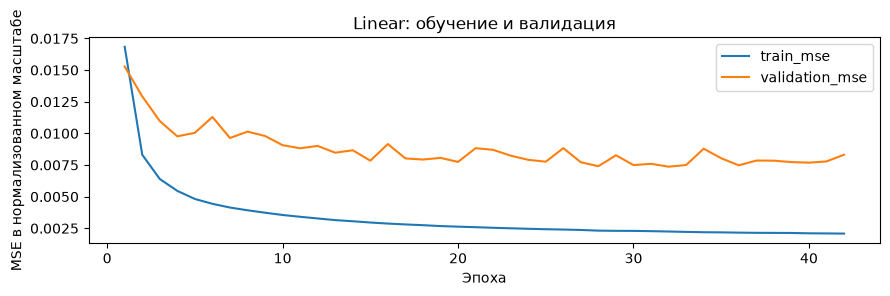

In [40]:
plot_history(histories['Linear'], 'Linear: обучение и валидация')

In [41]:
started = perf_counter()
restored_normalized = reconstruct(model, test)
times_model['Linear']['Тестирование, с'] = perf_counter()-started

In [42]:
restored = scaler.inverse_transform(restored_normalized.reshape(-1, 10))
test_linear = np.where(missing_masks['test'], restored, clean_splits['test'])

In [43]:
recovery_nn['Linear'] = test_linear

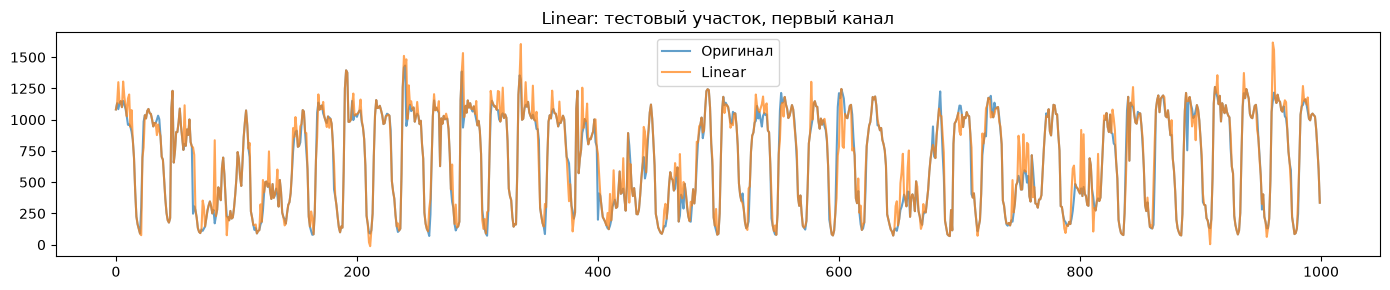

In [44]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(clean_splits['test'][:1000, 0], label='Оригинал', alpha=.7)
ax.plot(test_linear[:1000, 0], label='Linear', alpha=.7)
ax.set_title('Linear: тестовый участок, первый канал')
ax.legend(); plt.tight_layout(); plt.show()

##### 7.2.3 Реккурентная модель востановлениях данных


In [45]:
print('GRU encoder: 10 → 100, batch_first=True; latent size=100')

GRU encoder: 10 → 100, batch_first=True; latent size=100


In [46]:
print('GRU decoder: 100 → 10, batch_first=True; выход [batch, 100, 10]')

GRU decoder: 100 → 10, batch_first=True; выход [batch, 100, 10]


In [47]:
print(TimeAE.__name__)

TimeAE


In [48]:
torch.manual_seed(SEED)
model = TimeAE(size_subsequent=100, dim=10)

In [49]:
model

TimeAE(
  (encoder): GRU(10, 100, batch_first=True)
  (to_latent): Linear(in_features=10000, out_features=100, bias=True)
  (from_latent): Linear(in_features=100, out_features=10000, bias=True)
  (decoder): GRU(100, 10, batch_first=True)
  (activation): LeakyReLU(negative_slope=0.01)
)

In [50]:
history, duration = train_model(model, train, validation, validation_truth,
                                cache/'gru.pt', epochs=epochs, patience=patience)
histories['GRU'] = history
times_model['GRU'] = {'Обучение, с': duration}

gru: epoch 1, train=0.017485, validation=0.011294, elapsed=8.1s


gru: epoch 2, train=0.005377, validation=0.008930, elapsed=16.2s


gru: epoch 3, train=0.004123, validation=0.005526, elapsed=24.1s


gru: epoch 4, train=0.003367, validation=0.004736, elapsed=32.1s


gru: epoch 5, train=0.002907, validation=0.004199, elapsed=40.2s


...

gru: epoch 80, train=0.000868, validation=0.002158, elapsed=641.1s


gru: epoch 81, train=0.000861, validation=0.002165, elapsed=649.0s


gru: epoch 82, train=0.000852, validation=0.002272, elapsed=656.8s


gru: epoch 83, train=0.000851, validation=0.002184, elapsed=664.7s


gru: epoch 84, train=0.000843, validation=0.002153, elapsed=673.2s


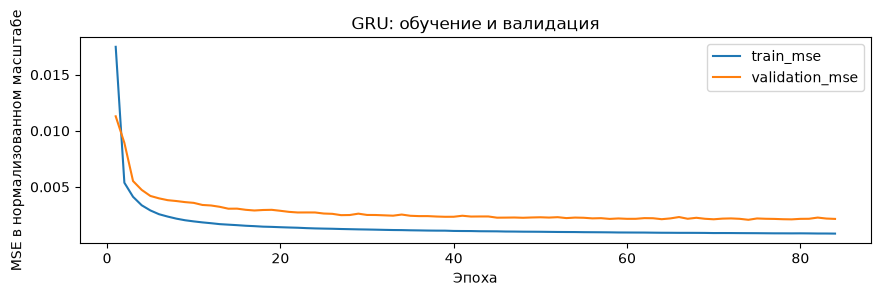

In [51]:
plot_history(histories['GRU'], 'GRU: обучение и валидация')

In [52]:
print('Лучшая эпоха GRU:', int(history.loc[history['validation_mse'].idxmin(), 'epoch']))

Лучшая эпоха GRU: 74


In [53]:
started = perf_counter()
restored_normalized = reconstruct(model, test)
times_model['GRU']['Тестирование, с'] = perf_counter()-started

In [54]:
restored = scaler.inverse_transform(restored_normalized.reshape(-1, 10))
test_ae = np.where(missing_masks['test'], restored, clean_splits['test'])

In [55]:
recovery_nn['GRU'] = test_ae

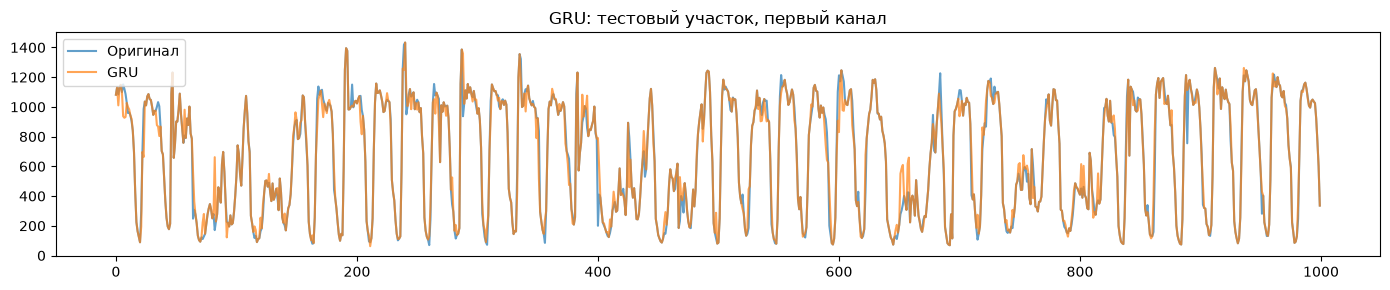

In [56]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(clean_splits['test'][:1000, 0], label='Оригинал', alpha=.7)
ax.plot(test_ae[:1000, 0], label='GRU', alpha=.7)
ax.set_title('GRU: тестовый участок, первый канал')
ax.legend(); plt.tight_layout(); plt.show()

##### 7.2.4 Сложные модели нейросетевого восстановления данных


Вам необходимо выбрать одну модель из 3 группы таблицы 7.2 и используя документацию произвести восстановления того же ряда. Произведите замер времени.

In [57]:
from pypots.imputation import SAITS
from pypots.optim import Adam as PyPOTSAdam

/Users/mikhail/Developer/2026-autumn/AFTSAIM-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



████████╗██╗███╗   ███╗███████╗    ███████╗███████╗██████╗ ██╗███████╗███████╗    █████╗ ██╗
╚══██╔══╝██║████╗ ████║██╔════╝    ██╔════╝██╔════╝██╔══██╗██║██╔════╝██╔════╝   ██╔══██╗██║
   ██║   ██║██╔████╔██║█████╗█████╗███████╗█████╗  ██████╔╝██║█████╗  ███████╗   ███████║██║
   ██║   ██║██║╚██╔╝██║██╔══╝╚════╝╚════██║██╔══╝  ██╔══██╗██║██╔══╝  ╚════██║   ██╔══██║██║
   ██║   ██║██║ ╚═╝ ██║███████╗    ███████║███████╗██║  ██║██║███████╗███████║██╗██║  ██║██║
   ╚═╝   ╚═╝╚═╝     ╚═╝╚══════╝    ╚══════╝╚══════╝╚═╝  ╚═╝╚═╝╚══════╝╚══════╝╚═╝╚═╝  ╚═╝╚═╝
ai4ts v0.0.3 - building AI for unified time-series analysis, https://time-series.ai 



In [58]:
torch.manual_seed(SEED)
np.random.seed(SEED)

In [59]:
model = SAITS(n_steps=100, n_features=10, n_layers=2,
              d_model=128, n_heads=4, d_k=32, d_v=32, d_ffn=128,
              dropout=.05, epochs=epochs, patience=patience, batch_size=64,
              optimizer=PyPOTSAdam(lr=.001), device='cpu', num_workers=0,
              saving_path=str(cache/'saits'), model_saving_strategy='best')
# PyPOTS writes TensorBoard scalars only for names containing loss/error.
model.validation_metric_name = 'MSE_loss'


2026-10-17 23:14:26 [INFO]: Using the given device: cpu


2026-10-17 23:14:26 [INFO]: Model files will be saved to .cache/saits/20261017_T231426


2026-10-17 23:14:26 [INFO]: Tensorboard file will be saved to .cache/saits/20261017_T231426/tensorboard


2026-10-17 23:14:26 [INFO]: Using customized MAE as the training loss function.


2026-10-17 23:14:26 [INFO]: Using customized MSE as the validation metric function.


2026-10-17 23:14:26 [INFO]: SAITS initialized with the given hyperparameters, the number of trainable parameters: 405,464


In [60]:
started = perf_counter()
model.fit({'X': train}, {'X': validation, 'X_ori': validation_truth})
times_model['SAITS'] = {'Обучение, с': perf_counter()-started}

2026-10-17 23:14:52 [INFO]: Epoch 001 - training loss (MAE): 0.2175, validation MSE_loss: 0.0074


2026-10-17 23:15:16 [INFO]: Epoch 002 - training loss (MAE): 0.1157, validation MSE_loss: 0.0065


2026-10-17 23:15:40 [INFO]: Epoch 003 - training loss (MAE): 0.0945, validation MSE_loss: 0.0056


2026-10-17 23:16:04 [INFO]: Epoch 004 - training loss (MAE): 0.0854, validation MSE_loss: 0.0049


2026-10-17 23:16:28 [INFO]: Epoch 005 - training loss (MAE): 0.0802, validation MSE_loss: 0.0044


...

2026-10-17 23:34:55 [INFO]: Epoch 049 - training loss (MAE): 0.0333, validation MSE_loss: 0.0016


2026-10-17 23:35:21 [INFO]: Epoch 050 - training loss (MAE): 0.0331, validation MSE_loss: 0.0016


2026-10-17 23:35:21 [INFO]: Exceeded the training patience. Terminating the training procedure...


2026-10-17 23:35:21 [INFO]: Finished training. The best model is from epoch#40.


2026-10-17 23:35:21 [INFO]: Saved the model to .cache/saits/20261017_T231426/SAITS.pypots


In [61]:
started = perf_counter()
restored_normalized = model.predict({'X': test})['imputation']
times_model['SAITS']['Тестирование, с'] = perf_counter()-started

In [62]:
restored = scaler.inverse_transform(restored_normalized.reshape(-1, 10))
test_saits = np.where(missing_masks['test'], restored, clean_splits['test'])

In [63]:
recovery_nn['SAITS'] = test_saits

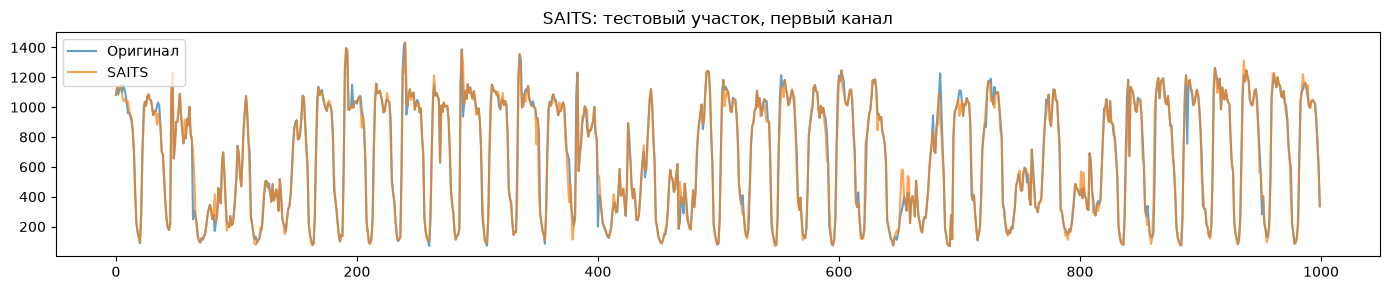

,MSE,RMSE,MAE,R2
Linear,31977.640224,178.822930,129.144335,0.828644
GRU,10447.711281,102.214046,66.364965,0.944015
SAITS,6772.638088,82.296039,50.405516,0.963708


,"Обучение, с","Тестирование, с"
Linear,30.046947,0.001820
GRU,673.223980,0.010533
SAITS,1254.523330,0.039080


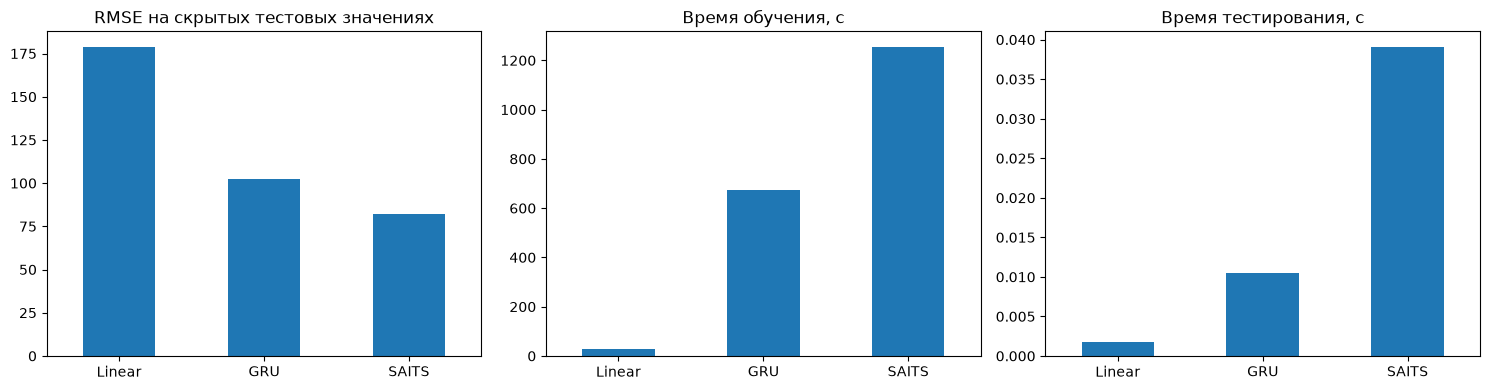

Лучший нейросетевой метод по RMSE: SAITS


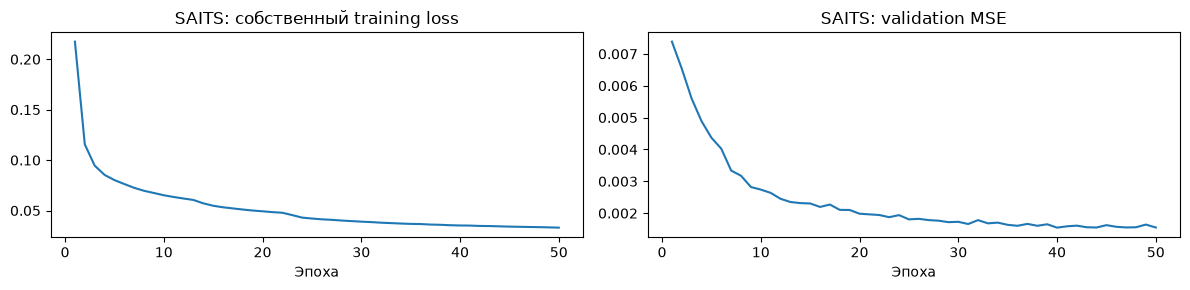

In [64]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(clean_splits['test'][:1000, 0], label='Оригинал', alpha=.7)
ax.plot(test_saits[:1000, 0], label='SAITS', alpha=.7)
ax.set_title('SAITS: тестовый участок, первый канал')
ax.legend(); plt.tight_layout(); plt.show()

neural_metrics = pd.DataFrame({name: masked_metrics(clean_splits['test'], values, missing_masks['test'])
                               for name, values in recovery_nn.items()}).T
for values in recovery_nn.values():
    np.testing.assert_array_equal(values[~missing_masks['test']], clean_splits['test'][~missing_masks['test']])
    assert np.isfinite(values).all()
display(neural_metrics)
time_table = pd.DataFrame(times_model).T
display(time_table)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
neural_metrics['RMSE'].plot.bar(ax=axes[0], rot=0, title='RMSE на скрытых тестовых значениях')
time_table['Обучение, с'].plot.bar(ax=axes[1], rot=0, title='Время обучения, с')
time_table['Тестирование, с'].plot.bar(ax=axes[2], rot=0, title='Время тестирования, с')
plt.tight_layout(); plt.show()
print('Лучший нейросетевой метод по RMSE:', neural_metrics['RMSE'].idxmin())
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
model.summary_writer.flush()
events = EventAccumulator(model.summary_writer.log_dir, size_guidance={'scalars': 0}).Reload()
train_events = events.Scalars('training/loss')
validation_events = events.Scalars('validating/MSE_loss')
steps_per_epoch = int(np.ceil(len(train) / 64))
train_curve = pd.Series([item.value for item in train_events],
                        index=[(item.step-1)//steps_per_epoch+1 for item in train_events]).groupby(level=0).mean()
val_curve = pd.Series([item.value for item in validation_events], index=[item.step for item in validation_events])
histories['SAITS'] = pd.DataFrame({'train_loss': train_curve, 'validation_mse': val_curve})
histories['SAITS'].index.name = 'epoch'
histories['SAITS'].to_csv(cache/'saits-history.csv')
saits_best_epoch = int(model.best_epoch)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
train_curve.plot(ax=axes[0], title='SAITS: собственный training loss')
val_curve.plot(ax=axes[1], title='SAITS: validation MSE')
for ax in axes:
    ax.set_xlabel('Эпоха')
plt.tight_layout(); plt.show()


##### 7.2.5 Сравнения результатов.
Также, как и в пункте 7.1.5 постройте графики сравнения моделей. Дополнительно постройте графики сравнения времени. Сделайте выводы

#### **7.3 Прогноз временного ряда**

##### *Краткое описание*

Используя модель и [ARIMA](реализация) произвидите прогноз ряда на следующие колличество точек: 1, 5, 10.
Сравните результаты. Постройте графики прогноза и точности прогноза.

ARIMA converged: True


,MAE,RMSE
Горизонт,,
1,295.201223,295.201223
5,861.005057,908.027508
10,918.868164,943.291179


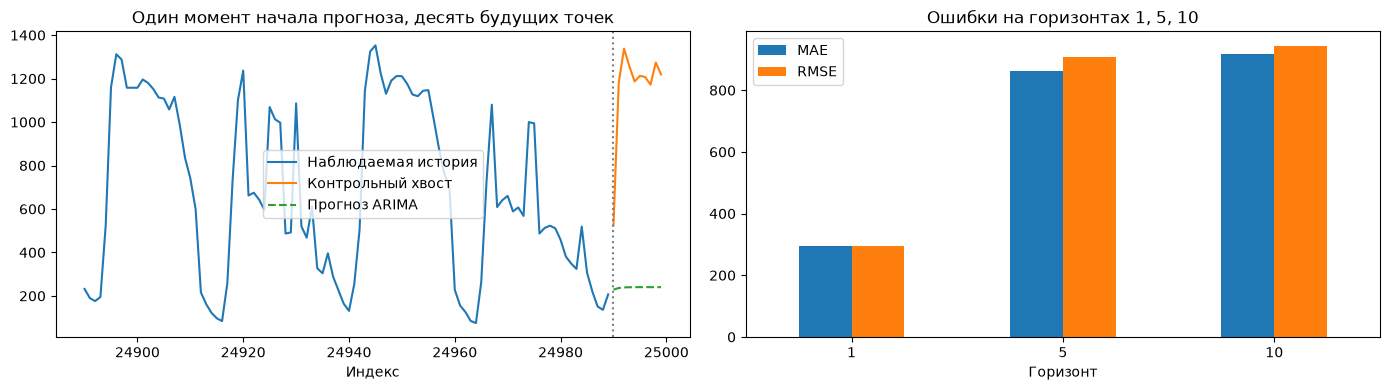

In [65]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_train = madrid_matrix[:-10, 0].copy()
forecast_truth = madrid_matrix[-10:, 0].copy()
forecast_model = ARIMA(forecast_train, order=(1, 1, 1)).fit()
forecast = np.asarray(forecast_model.forecast(steps=10))
assert len(forecast) == 10 and np.isfinite(forecast).all()
print('ARIMA converged:', forecast_model.mle_retvals.get('converged'))
forecast_metrics = pd.DataFrame({
    h: {'MAE': mean_absolute_error(forecast_truth[:h], forecast[:h]),
        'RMSE': np.sqrt(mean_squared_error(forecast_truth[:h], forecast[:h]))}
    for h in [1, 5, 10]
}).T
forecast_metrics.index.name = 'Горизонт'
display(forecast_metrics)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(np.arange(24890, 24990), forecast_train[-100:], label='Наблюдаемая история')
axes[0].plot(np.arange(24990, 25000), forecast_truth, label='Контрольный хвост')
axes[0].plot(np.arange(24990, 25000), forecast, '--', label='Прогноз ARIMA')
axes[0].axvline(24990, color='grey', linestyle=':')
axes[0].set(title='Один момент начала прогноза, десять будущих точек', xlabel='Индекс')
axes[0].legend()
forecast_metrics.plot.bar(ax=axes[1], rot=0, title='Ошибки на горизонтах 1, 5, 10')
plt.tight_layout(); plt.show()

## Результаты и ограничения

### Нейросетевое восстановление

| Метод | MSE | RMSE | MAE | R² |
|---|---:|---:|---:|---:|
| Linear | 31977.6402 | 178.8229 | 129.1443 | 0.8286 |
| GRU | 10447.7113 | 102.2140 | 66.3650 | 0.9440 |
| SAITS | 6772.6381 | 82.2960 | 50.4055 | 0.9637 |

На одной тестовой маске 12500 пропусков всех десяти каналов лучший RMSE получил **SAITS**: **82.2960**. Тест — последние 5000 отсчётов; он не использован для обучения, нормализации или выбора эпохи. Обучающий и валидационный участки отделены до формирования окон. Метрики приведены в исходном масштабе, только для скрытых тестовых элементов.

| Модель | Выполнено эпох | Лучшая эпоха | Обучение, с | Тестирование, с |
|---|---:|---:|---:|---:|
| Linear | 42 | 32 | 30.05 | 0.0018 |
| GRU | 84 | 74 | 673.22 | 0.0105 |
| SAITS | 50 | 40 | 1254.52 | 0.0391 |

Обучение ограничено 100 эпохами; остановка — после 10 эпох без улучшения валидационной MSE. Для оценки восстановлено лучшее состояние. Linear и GRU используют MSE по дополнительно скрытым известным значениям; SAITS — собственный loss ORT/MIT библиотеки. Результаты алгоритмического восстановления первого канала по всему ряду и нейросетей на многомерном тесте показаны отдельными таблицами: их RMSE нельзя напрямую использовать для общего ранжирования.

SAITS снизила тестовый RMSE относительно GRU на 19.5%. Linear дала наибольшую ошибку среди трёх сетей. Обучение SAITS заняло 1254,52 с против 673,22 с у GRU и 30,05 с у Linear; более точное восстановление потребовало больше времени обучения.

### ARIMA

ARIMA(1,1,1) обучена на первых 24990 исходных значениях первого канала. Последние десять значений служат контрольным будущим; горизонты используют один и тот же момент начала прогноза. Модель сошлась.

| Горизонт | MAE | RMSE |
|---:|---:|---:|
| 1 | 295.201223 | 295.201223 |
| 5 | 861.005057 | 908.027508 |
| 10 | 918.868164 | 943.291179 |

Ошибка относится к одному контрольному хвосту, а не к независимому набору моментов прогноза. Порядок ARIMA не подбирался по этому хвосту. Пропуски для восстановления создавались в отдельных экспериментах и не использовались при обучении ARIMA.

Фиксированная ARIMA(1,1,1) плохо восстановила динамику контрольного хвоста: прогноз приблизился к уровню 240, тогда как после первой контрольной точки ряд вырос до 1183–1338. RMSE увеличилась с 295,20 на горизонте 1 до 943,29 на горизонте 10. Сходимость оптимизатора не гарантирует точности прогноза; порядок модели оставлен заранее заданным.

In [66]:
import json

assert index.sum() == 6250
for name, mask in missing_masks.items():
    assert mask.sum() == int(clean_splits[name].size * .25)
assert train.shape == (14901, 100, 10)
assert validation.shape == test.shape == (50, 100, 10)
np.testing.assert_array_equal(scaler.data_min_, np.nanmin(damaged_splits['train'], axis=0))
np.testing.assert_array_equal(scaler.data_max_, np.nanmax(damaged_splits['train'], axis=0))
assert len(forecast_train) == len(madrid_matrix)-10
np.testing.assert_array_equal(forecast_train, madrid_matrix[:-10, 0])
assert np.isfinite(analytic_metrics.to_numpy()).all()
assert np.isfinite(neural_metrics.to_numpy()).all()
assert np.isfinite(forecast_metrics.to_numpy()).all()
assert all(len(history) <= 100 for history in histories.values())
assert all(np.isfinite(history['validation_mse']).all() for history in histories.values())
summary = {
    'analytic': analytic_metrics.to_dict(orient='index'),
    'best_analytic': best_analytic,
    'best_per_group': best_methods,
    'neural': neural_metrics.to_dict(orient='index'),
    'times': times_model,
    'epochs': {name: len(history) for name, history in histories.items()},
    'best_epochs': {**{name: int(history.loc[history['validation_mse'].idxmin(), 'epoch'])
                       for name, history in histories.items() if name != 'SAITS'},
                    'SAITS': saits_best_epoch},
    'forecast': forecast_metrics.to_dict(orient='index'),
    'arima_converged': bool(forecast_model.mle_retvals.get('converged')),
    'forecast_values': forecast.tolist(),
    'forecast_truth': forecast_truth.tolist(),
}
(cache/'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
np.savez_compressed(cache/'restored-test.npz', truth=clean_splits['test'], mask=missing_masks['test'],
                    **recovery_nn)
print('Проверки полного запуска пройдены')

Проверки полного запуска пройдены
